# PCA Biplot

**Family:** Multivariate & ML &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Multivariate & ML:* Explore many variables at once and explain or diagnose statistical and machine-learning models.

## Design purpose

Projects many correlated numeric variables onto the first two principal components. It draws the observations as points and the original variables as arrows (loadings), so you see at once how the samples group and which variables drive that grouping.

## When to use

- Get an overview of a dataset with many numeric variables (5–50)
- See which variables pull observations apart, and which variables are correlated (arrows pointing the same way)
- Check visually whether known groups separate in the main directions of variation

## Avoid when

- The first two components explain little of the variance (check the axis labels; under ~40% the picture is misleading)
- Variables are on different scales and you have not standardized them
- The audience is non-technical (principal components have no plain-language units)

## Alternatives

- t-SNE / UMAP embedding (for non-linear structure)
- Pair plot (for fewer than ~6 variables)
- Correlation heatmap

## Design tips

- Always standardize variables first, unless they share a unit
- Put the % of variance explained on each axis label
- Label only the longest arrows; a hedgehog of 30 labeled arrows is unreadable

## Example

The real UCI Wine dataset bundled with scikit-learn (load_wine). It has 178 wines from three Italian cultivars and 13 chemical measurements.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

### Data

In [2]:
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target.map(lambda k: f"Cultivar {k}")
Z = StandardScaler().fit_transform(X)
pca = PCA(n_components=2).fit(Z)
scores = pca.transform(Z)
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"])
loadings.round(2).sort_values("PC1")

,PC1,PC2
nonflavanoid_phenols,-0.30,0.03
malic_acid,-0.25,0.22
alcalinity_of_ash,-0.24,-0.01
color_intensity,-0.09,0.53
ash,-0.00,0.32
alcohol,0.14,0.48
magnesium,0.14,0.30
proline,0.29,0.36
hue,0.30,-0.28
proanthocyanins,0.31,0.04


### Plot

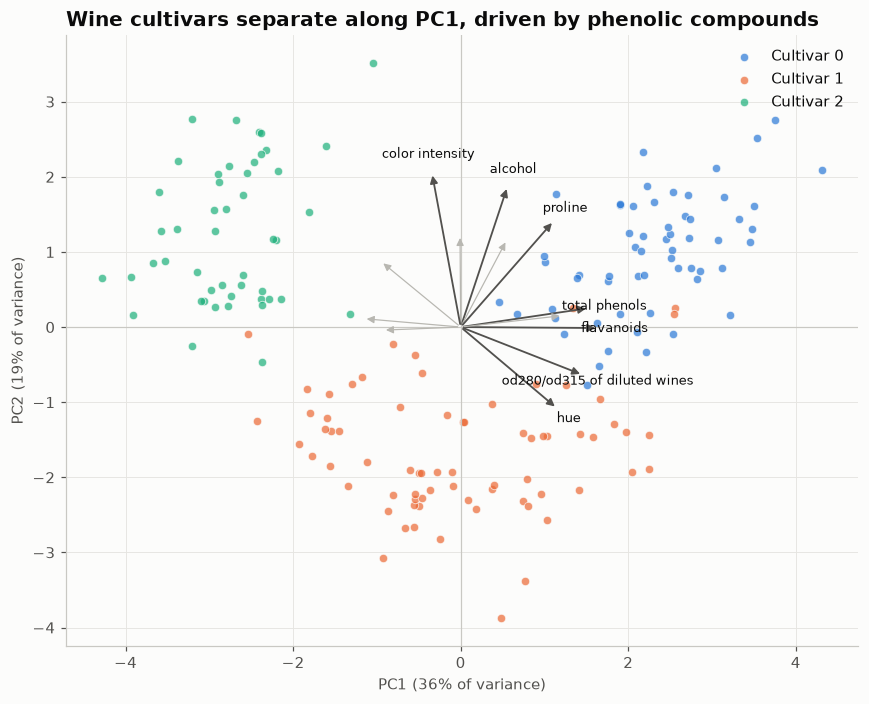

In [3]:
fig, ax = plt.subplots(figsize=(8, 6.5))
for color, cls in zip(PALETTE, sorted(y.unique())):
    m = (y == cls).values
    ax.scatter(scores[m, 0], scores[m, 1], s=30, alpha=0.7, color=color,
               edgecolor="#fcfcfb", linewidth=0.6, label=cls)
scale = np.abs(scores).max() * 0.9
top = loadings.pow(2).sum(axis=1).nlargest(7).index
for name, (lx, ly) in loadings.iterrows():
    strong = name in top
    ax.annotate("", xy=(lx * scale, ly * scale), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color="#52514e" if strong else "#b8b7b1",
                                lw=1.2 if strong else 0.8))
    if strong:
        ax.text(lx * scale * 1.12, ly * scale * 1.12, name.replace("_", " "), fontsize=8.5,
                color="#0b0b0b", ha="center", va="center")
ev = pca.explained_variance_ratio_ * 100
ax.set_xlabel(f"PC1 ({ev[0]:.0f}% of variance)")
ax.set_ylabel(f"PC2 ({ev[1]:.0f}% of variance)")
ax.axhline(0, color="#c9c8c3", lw=0.8)
ax.axvline(0, color="#c9c8c3", lw=0.8)
ax.set_title("Wine cultivars separate along PC1, driven by phenolic compounds")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

## How to read it

Each dot is a wine. The three cultivars form three distinct clouds. Arrows point towards wines with high values of that variable. Flavanoids and total phenols point towards cultivar 0, so those wines are rich in phenolics. Color intensity points towards cultivar 2, and cultivar 1 sits opposite alcohol and proline, meaning lighter, less alcoholic wines. (The sign of a principal component is arbitrary, so another tool may show the picture mirrored.)

---
Standalone script: [`pca_biplot.py`](pca_biplot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)